In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

df = pd.read_csv("data/Housing.csv")
print("Shape:", df.shape)
df.head()

Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
df.info()
print(df.isnull().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwater

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [3]:
#Step 2: Preprocess 
#Concept: linear regression needs numbers only. Yes/no columns become 1/0, and furnishingstatus (3 categories) gets one-hot encoded.

yes_no_cols = ["mainroad", "guestroom", "basement", "hotwaterheating",
               "airconditioning", "prefarea"]
for col in yes_no_cols:
    df[col] = df[col].map({"yes": 1, "no": 0})

df = pd.get_dummies(df, columns=["furnishingstatus"], drop_first=True, dtype=int)
df.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


In [4]:
print(df.isnull().sum().sum(), "missing values")
print(df.dtypes)

0 missing values
price                              int64
area                               int64
bedrooms                           int64
bathrooms                          int64
stories                            int64
mainroad                           int64
guestroom                          int64
basement                           int64
hotwaterheating                    int64
airconditioning                    int64
parking                            int64
prefarea                           int64
furnishingstatus_semi-furnished    int64
furnishingstatus_unfurnished       int64
dtype: object


In [5]:
# Step 3: Simple linear regression 
#Concept: simple regression predicts price from one feature, area. This is the one you can plot as a line.

X_simple = df[["area"]]
y = df["price"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

y_pred_s = simple_model.predict(X_test_s)

print("Intercept:", round(simple_model.intercept_, 2))
print("Coefficient (area):", round(simple_model.coef_[0], 2))

Intercept: 2512254.26
Coefficient (area): 425.73


In [6]:
#Evaluate the simple model 
def evaluate(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"{label}")
    print(f"  MAE : {mae:,.2f}")
    print(f"  MSE : {mse:,.2f}")
    print(f"  RMSE: {rmse:,.2f}")
    print(f"  R²  : {r2:.4f}\n")

evaluate(y_test_s, y_pred_s, "Simple Linear Regression (area only)")

Simple Linear Regression (area only)
  MAE : 1,474,748.13
  MSE : 3,675,286,604,768.19
  RMSE: 1,917,103.70
  R²  : 0.2729



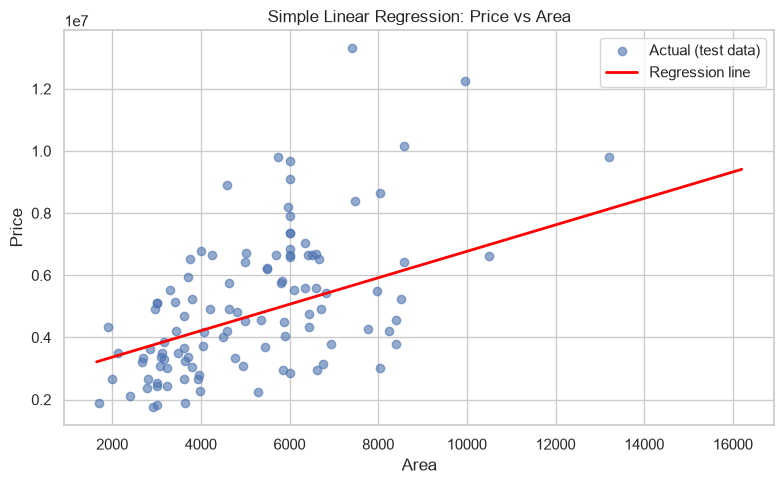

In [7]:
# Plot the regression line
plt.figure(figsize=(8, 5))
plt.scatter(X_test_s, y_test_s, alpha=0.6, label="Actual (test data)")
line_x = np.linspace(X_simple["area"].min(), X_simple["area"].max(), 100).reshape(-1, 1)
line_y = simple_model.predict(pd.DataFrame(line_x, columns=["area"]))
plt.plot(line_x, line_y, color="red", linewidth=2, label="Regression line")
plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Simple Linear Regression: Price vs Area")
plt.legend()
plt.tight_layout()
plt.savefig("images/simple_regression_line.png", dpi=150)
plt.show()

In [8]:
# Multiple linear regression
# Concept: multiple regression uses several features together to predict price.
X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

evaluate(y_test, y_pred, "Multiple Linear Regression (all features)")

Multiple Linear Regression (all features)
  MAE : 970,043.40
  MSE : 1,754,318,687,330.66
  RMSE: 1,324,506.96
  R²  : 0.6529



In [9]:
# Interpret the coefficients
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values("Coefficient", ascending=False)

print("Intercept:", round(model.intercept_, 2))
coef_df

Intercept: 260032.36


,Feature,Coefficient
2,bathrooms,1.094445e+06
8,airconditioning,7.914267e+05
7,hotwaterheating,6.846499e+05
10,prefarea,6.298906e+05
3,stories,4.074766e+05
6,basement,3.902512e+05
4,mainroad,3.679199e+05
5,guestroom,2.316100e+05
9,parking,2.248419e+05
1,bedrooms,7.677870e+04


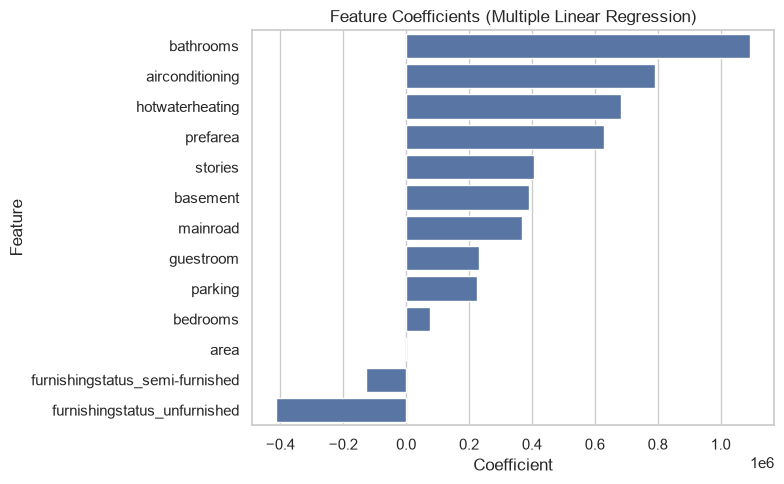

In [10]:
plt.figure(figsize=(8, 5))
sns.barplot(x="Coefficient", y="Feature", data=coef_df)
plt.title("Feature Coefficients (Multiple Linear Regression)")
plt.tight_layout()
plt.savefig("images/coefficients.png", dpi=150)
plt.show()

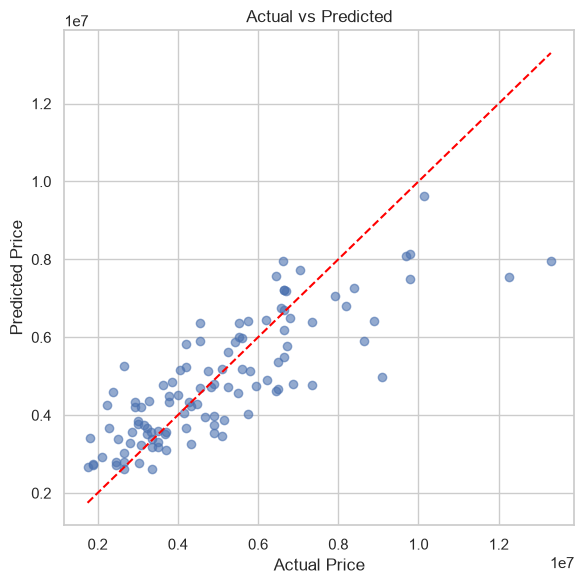

In [11]:
# Check the model
# Actual vs predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, color="red", linestyle="--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.savefig("images/actual_vs_predicted.png", dpi=150)
plt.show()

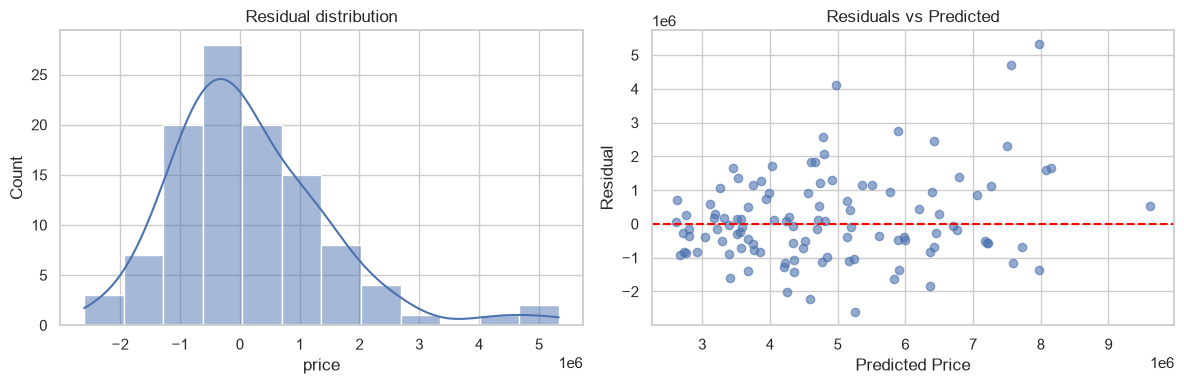

In [12]:
# Residuals
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title("Residual distribution")
axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs Predicted")
plt.tight_layout()
plt.savefig("images/residuals.png", dpi=150)
plt.show()